In [2]:
import pandas as pd
import sqlite3
from pathlib import Path

RAW = Path("../data/raw")
conn = sqlite3.connect("../olist.db")

for csv in RAW.glob("*.csv"):
    nome = csv.stem.replace("olist_", "").replace("_dataset", "")
    df = pd.read_csv(csv)
    df.to_sql(nome, conn, if_exists="replace", index=False)
    print(f"{nome:35} {df.shape[0]:>8} linhas | {df.shape[1]:>2} colunas | "
          f"{df.isna().sum().sum():>7} nulos")

conn.close()

customers                              99441 linhas |  5 colunas |       0 nulos
geolocation                          1000163 linhas |  5 colunas |       0 nulos
orders                                 99441 linhas |  8 colunas |    4908 nulos
order_items                           112650 linhas |  7 colunas |       0 nulos
order_payments                        103886 linhas |  5 colunas |       0 nulos
order_reviews                          99224 linhas |  7 colunas |  145903 nulos
products                               32951 linhas |  9 colunas |    2448 nulos
sellers                                 3095 linhas |  4 colunas |       0 nulos
product_category_name_translation         71 linhas |  2 colunas |       0 nulos


In [3]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../olist.db")

pd.read_sql("""
    SELECT order_status, COUNT(*) AS pedidos
    FROM orders
    GROUP BY order_status
    ORDER BY pedidos DESC
""", conn)

,order_status,pedidos
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [4]:
import matplotlib.pyplot as plt

query = open("../sql/01_vendas_mensais.sql").read()
vendas = pd.read_sql(query, conn)
vendas

,mes,pedidos,receita,ticket_medio,crescimento_pct
0,2016-09,2,207.86,103.93,NaN
1,2016-10,290,44507.30,153.47,21312.2
2,2016-12,1,10.90,10.90,-100.0
3,2017-01,787,120098.27,152.60,1101719.0
4,2017-02,1718,244959.35,142.58,104.0
5,2017-03,2617,368341.32,140.75,50.4
6,2017-04,2377,353842.98,148.86,-3.9
7,2017-05,3640,503159.19,138.23,42.2
8,2017-06,3205,429916.61,134.14,-14.6
9,2017-07,3946,492287.30,124.76,14.5


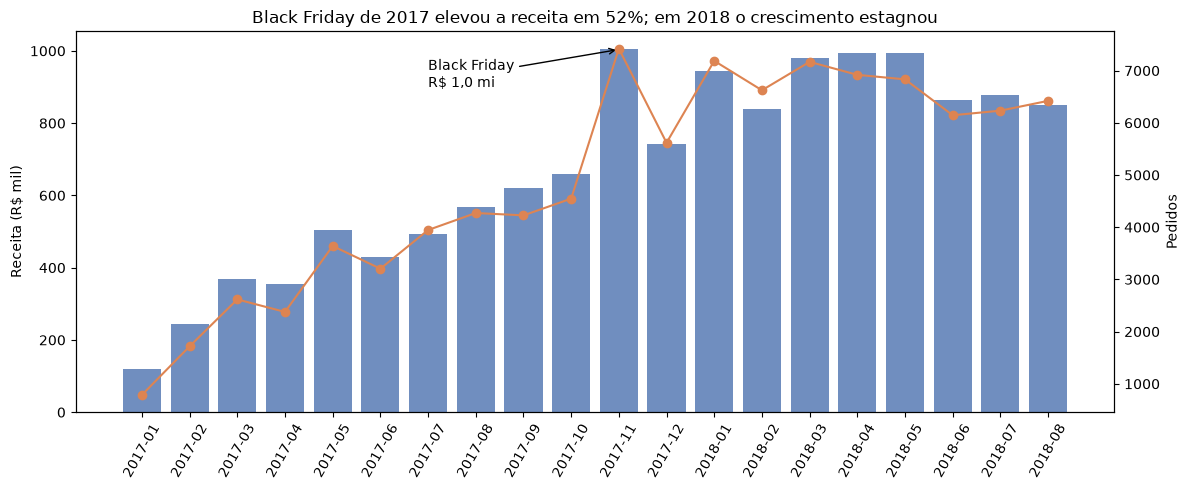

In [7]:
# Período completo e consistente 
v = vendas[(vendas["mes"] >= "2017-01") & (vendas["mes"] <= "2018-08")]

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(v["mes"], v["receita"] / 1000, color="#4C72B0", alpha=0.8)
ax1.set_ylabel("Receita (R$ mil)")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(v["mes"], v["pedidos"], color="#DD8452", marker="o")
ax2.set_ylabel("Pedidos")

ax1.set_title("Black Friday de 2017 elevou a receita em 52%; em 2018 o crescimento estagnou")
ax1.annotate("Black Friday\nR$ 1,0 mi", xy=("2017-11", 1003.8),
             xytext=("2017-07", 900),
             arrowprops=dict(arrowstyle="->"), fontsize=10)
plt.tight_layout()
plt.savefig("../images/01_vendas_mensais.png", dpi=150)
plt.show()

In [18]:
query = open("../sql/02_categorias.sql").read()
cat = pd.read_sql(query, conn)
cat.head(15)

,categoria,pedidos,receita,pct_receita,nota_media,rank_receita,rank_pior_nota
0,health_beauty,8800,1255695.13,9.3,4.19,1,37.0
1,watches_gifts,5604,1198185.21,8.9,4.07,2,20.0
2,bed_bath_table,9399,1035964.06,7.7,3.97,3,9.0
3,sports_leisure,7673,979740.92,7.3,4.18,4,35.0
4,computers_accessories,6654,904322.02,6.7,4.04,5,14.0
5,furniture_decor,6425,727465.05,5.4,4.02,6,12.0
6,housewares,5847,626825.80,4.6,4.16,7,31.0
7,cool_stuff,3616,620770.49,4.6,4.18,8,35.0
8,auto,3872,586585.73,4.3,4.11,9,26.0
9,garden_tools,3505,481009.94,3.6,4.15,10,29.0


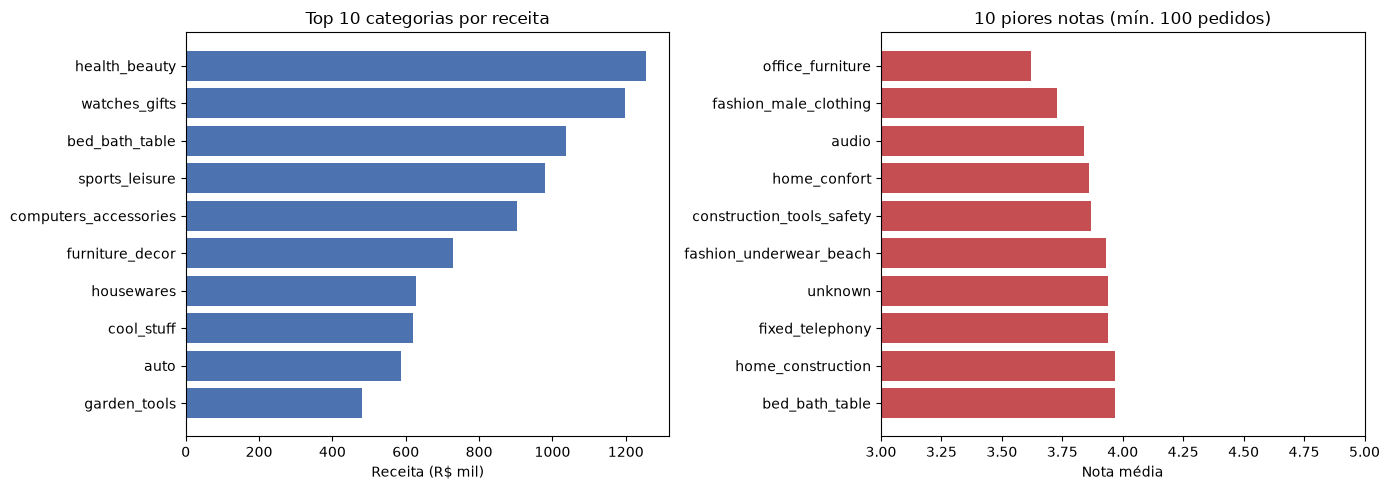

In [19]:
top_receita = cat.nsmallest(10, "rank_receita").sort_values("receita")
piores_notas = (cat[cat["rank_pior_nota"] <= 10]
                .sort_values("nota_media", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(top_receita["categoria"], top_receita["receita"] / 1000, color="#4C72B0")
axes[0].set_title("Top 10 categorias por receita")
axes[0].set_xlabel("Receita (R$ mil)")

axes[1].barh(piores_notas["categoria"], piores_notas["nota_media"], color="#C44E52")
axes[1].set_title("10 piores notas (mín. 100 pedidos)")
axes[1].set_xlabel("Nota média")
axes[1].set_xlim(3, 5)

plt.tight_layout()
plt.savefig("../images/02_categorias.png", dpi=150)
plt.show()

In [20]:
conn = sqlite3.connect("../olist.db")  # reabra se a conexão estiver fechada

query = open("../sql/03_entregas_estado.sql").read()
est = pd.read_sql(query, conn)
est

,estado,pedidos,prazo_medio_dias,dias_vs_estimado_medio,pct_atraso,rank_prazo
0,RR,41,29.4,-17.3,12.2,1
1,AP,67,27.2,-19.7,3.0,2
2,AM,145,26.4,-19.6,2.8,3
3,AL,397,24.5,-8.7,21.4,4
4,PA,946,23.8,-14.1,11.2,5
5,MA,717,21.6,-9.6,17.4,6
6,SE,335,21.5,-10.0,15.2,7
7,CE,1279,21.3,-10.8,13.8,8
8,AC,80,21.0,-20.7,3.8,9
9,PB,517,20.4,-13.3,10.4,10


In [21]:
atraso_geral = (est["pct_atraso"] * est["pedidos"]).sum() / est["pedidos"].sum()
print(f"Atraso geral: {atraso_geral:.1f}%")

Atraso geral: 6.8%


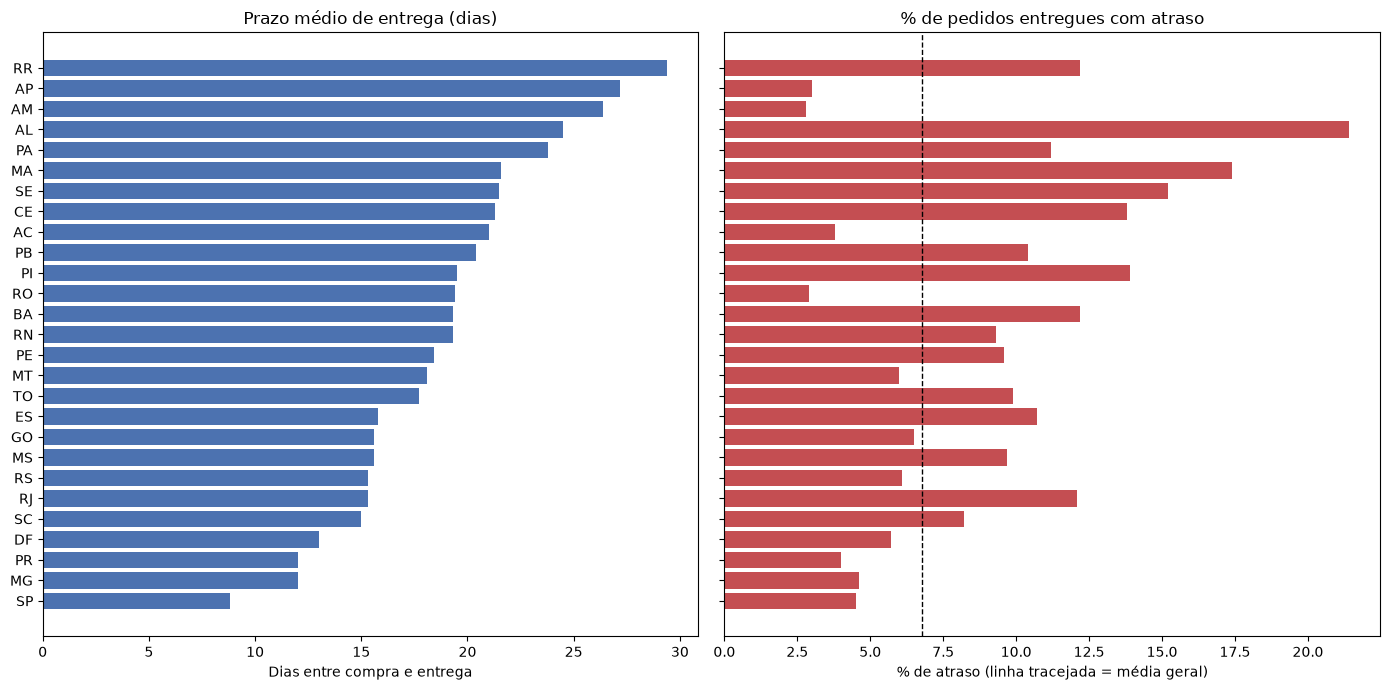

In [24]:
e = est.sort_values("prazo_medio_dias")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

axes[0].barh(e["estado"], e["prazo_medio_dias"], color="#4C72B0")
axes[0].set_title("Prazo médio de entrega (dias)")
axes[0].set_xlabel("Dias entre compra e entrega")

axes[1].barh(e["estado"], e["pct_atraso"], color="#C44E52")
axes[1].axvline(atraso_geral, color="black", linestyle="--", linewidth=1)
axes[1].set_title("% de pedidos entregues com atraso")
axes[1].set_xlabel("% de atraso (linha tracejada = média geral)")

plt.tight_layout()
plt.savefig("../images/03_entregas_estado.png", dpi=150)
plt.show()

In [6]:
conn = sqlite3.connect("../olist.db")

query = open("../sql/04_atraso_nota.sql").read()
atraso = pd.read_sql(query, conn)
atraso

,faixa,pedidos,pct_pedidos,nota_media,pct_nota_baixa
0,1. Antes do prazo,88163,92.0,4.29,9.2
1,2. No dia estimado,1280,1.3,4.04,12.3
2,3. Atraso 1-3 dias,1852,1.9,3.29,32.2
3,4. Atraso 4-7 dias,1748,1.8,2.11,67.6
4,5. Atraso 8+ dias,2781,2.9,1.70,79.2


In [5]:
query = open("../sql/04b_categoria_atraso.sql").read()
cat_atraso = pd.read_sql(query, conn)
cat_atraso.head(15)

,categoria,pedidos,pct_atraso,nota_media,nota_no_prazo
0,office_furniture,1244,8.0,3.64,3.75
1,fashion_male_clothing,105,3.8,3.82,3.89
2,audio,345,11.6,3.84,4.12
3,home_confort,390,9.5,3.89,4.06
4,construction_tools_safety,158,2.5,3.97,4.05
5,fixed_telephony,209,4.3,3.97,4.06
6,home_construction,481,6.0,3.99,4.08
7,bed_bath_table,9177,7.3,4.00,4.14
8,fashion_underwear_beach,116,9.5,4.01,4.26
9,unknown,1382,7.2,4.01,4.16


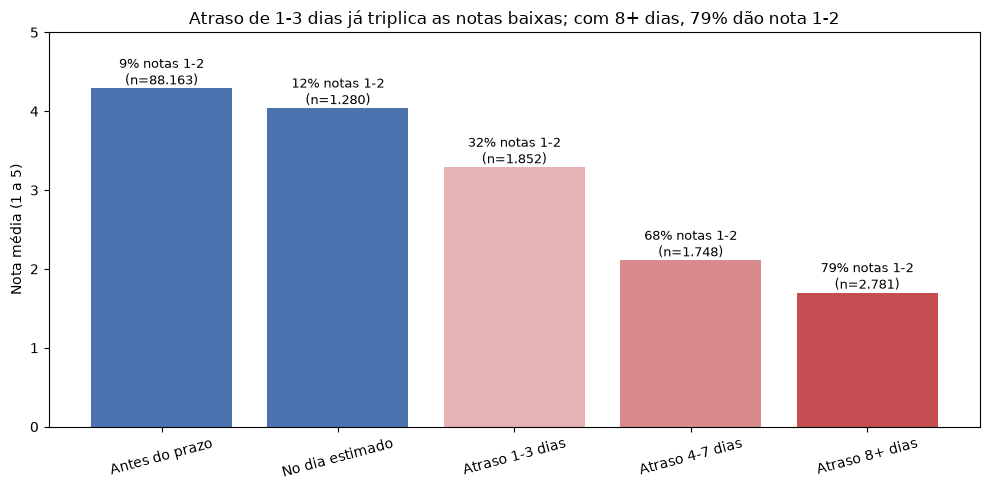

In [7]:
a = atraso.copy()
a["faixa_label"] = a["faixa"].str[3:]
cores = ["#4C72B0", "#4C72B0", "#E5B3B4", "#D98A8C", "#C44E52"]

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(a["faixa_label"], a["nota_media"], color=cores)

for b, pct, n in zip(barras, a["pct_nota_baixa"], a["pedidos"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05,
            f"{pct:.0f}% notas 1-2\n(n={n:,})".replace(",", "."),
            ha="center", fontsize=9)

ax.set_ylim(0, 5)
ax.set_ylabel("Nota média (1 a 5)")
ax.set_title("Atraso de 1-3 dias já triplica as notas baixas; com 8+ dias, 79% dão nota 1-2")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../images/04_atraso_nota.png", dpi=150)
plt.show()

In [5]:
conn = sqlite3.connect("../olist.db")

query = open("../sql/05_recompra.sql").read()
recompra = pd.read_sql(query, conn)
recompra

taxa = recompra.loc[recompra["faixa"] != "1 pedido", "clientes"].sum() / recompra["clientes"].sum()
print(f"Taxa de recompra: {taxa:.1%}")

Taxa de recompra: 3.0%


In [5]:
query = open("../sql/05b_primeira_compra.sql").read()
base = pd.read_sql(query, conn)

print(f"Taxa de recompra na coorte: {base['recomprou'].mean():.1%}")

# Por atraso na primeira compra
por_atraso = base.groupby("atraso")["recomprou"].agg(clientes="count", taxa="mean")
por_atraso["taxa"] = (por_atraso["taxa"] * 100).round(2)
por_atraso.index = ["No prazo", "Com atraso"]
print(por_atraso)

# Por nota da primeira compra
b = base.dropna(subset=["nota"]).copy()
b["grupo_nota"] = pd.cut(b["nota"], [0, 2, 3, 5], labels=["Nota 1-2", "Nota 3", "Nota 4-5"])
por_nota = b.groupby("grupo_nota", observed=True)["recomprou"].agg(clientes="count", taxa="mean")
por_nota["taxa"] = (por_nota["taxa"] * 100).round(2)
print(por_nota)

Taxa de recompra na coorte: 4.0%
            clientes  taxa
No prazo       51560  4.09
Com atraso      3667  3.05
            clientes  taxa
grupo_nota                
Nota 1-2        7182  3.63
Nota 3          4798  3.96
Nota 4-5       42838  4.10


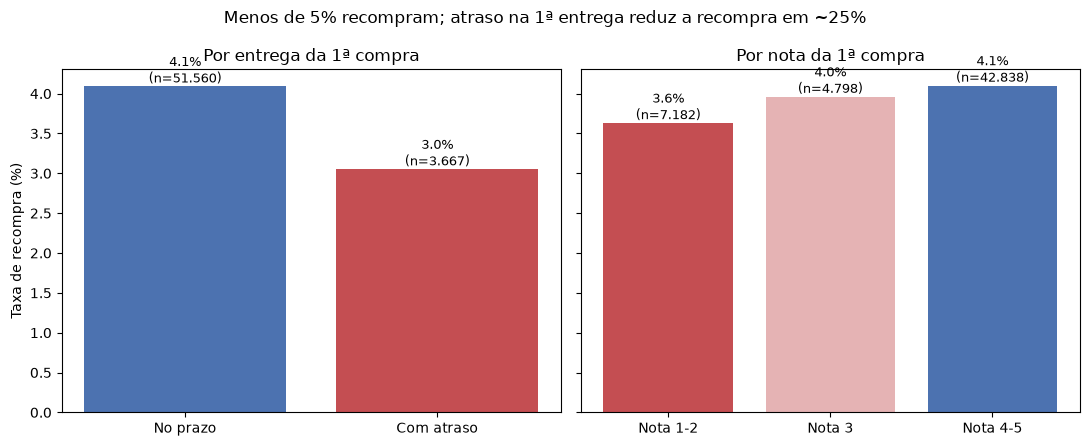

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

axes[0].bar(por_atraso.index, por_atraso["taxa"], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Por entrega da 1ª compra")
axes[0].set_ylabel("Taxa de recompra (%)")

axes[1].bar(por_nota.index.astype(str), por_nota["taxa"],
            color=["#C44E52", "#E5B3B4", "#4C72B0"])
axes[1].set_title("Por nota da 1ª compra")

for ax, d in zip(axes, [por_atraso, por_nota]):
    for i, (t, n) in enumerate(zip(d["taxa"], d["clientes"])):
        ax.text(i, t + 0.05, f"{t:.1f}%\n(n={n:,})".replace(",", "."), ha="center", fontsize=9)

fig.suptitle("Menos de 5% recompram; atraso na 1ª entrega reduz a recompra em ~25%")
plt.tight_layout()
plt.savefig("../images/05_recompra.png", dpi=150)
plt.show()

In [6]:
import sqlite3
import pandas as pd
from pathlib import Path

conn = sqlite3.connect("../olist.db")
query = open("../sql/05b_primeira_compra.sql").read()
base = pd.read_sql(query, conn)

base["entrega_1a_compra"] = base["atraso"].map({0: "No prazo", 1: "Com atraso"})
base["grupo_nota"] = (pd.cut(base["nota"], [0, 2, 3, 5],
                             labels=["Nota 1-2", "Nota 3", "Nota 4-5"])
                      .astype("object").fillna("Sem nota"))

Path("../data/processed").mkdir(parents=True, exist_ok=True)
base.to_csv("../data/processed/primeira_compra.csv", index=False)

print(base.shape)
base.head()

(55227, 6)


,cliente,atraso,nota,recomprou,entrega_1a_compra,grupo_nota
0,0000f46a3911fa3c0805444483337064,0,3.0,0,No prazo,Nota 3
1,0000f6ccb0745a6a4b88665a16c9f078,0,4.0,0,No prazo,Nota 4-5
2,0004aac84e0df4da2b147fca70cf8255,0,5.0,0,No prazo,Nota 4-5
3,00053a61a98854899e70ed204dd4bafe,0,1.0,0,No prazo,Nota 1-2
4,0005e1862207bf6ccc02e4228effd9a0,0,4.0,0,No prazo,Nota 4-5
